# 24_DBSCAN

# DBSCAN — Density-Based Clustering

## Learning Objectives

- K-Means와 DBSCAN의 Cluster 구성 방법이 어떻게 다른지 설명한다.
- `eps`와 `min_samples`로 Core, Border, Noise를 판별한다.
- DBSCAN으로 굽은 형태의 Cluster를 발견하고 시각화한다.
- `eps`를 변경한 결과를 Cluster 수와 Noise 수로 해석한다.

이번 강의의 질문은 다음과 같다.

> 중심점을 정하지 않고도, 가까운 Data가 밀집한 영역을 찾아 Cluster를 만들 수 있을까?

## From K-Means to DBSCAN

23강 K-Means는 `k`개의 Centroid를 정하고, 각 Sample을 가장 가까운 Centroid에 할당했다.

- K-Means: Centroid 기반 Clustering. `k`를 먼저 지정해야 한다.
- DBSCAN: 밀집된 영역을 연결하여 Cluster를 구성한다. `k`를 먼저 지정하지 않는다.
- DBSCAN은 어떤 Cluster에도 속하지 않는 Sample을 Noise로 표시할 수 있다.

굽은 두 Group과 주변의 Noise를 생각해 보자. 이런 Data는 Centroid를 중심으로 나누기 어렵다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors

# Google Drive의 0_ML/Input 폴더에 CSV를 저장해 둔다.
from google.colab import drive
drive.mount('/content/drive')
data_path = '/content/drive/My Drive/Colab Notebooks/0_ML/Input/'

Mounted at /content/drive


## Data — Discovering Groups Without Labels

강의용 `dbscan_data.csv`는 `x1`, `x2` 두 Feature만 가진다.

- `y` 또는 정답 Class는 제공하지 않는다.
- 아래 그림에서 Data의 형태를 먼저 관찰한다.
- Cluster 개수와 Noise 개수를 미리 정하지 않는다.

In [2]:
# CSV를 읽고 전체 크기와 첫 부분을 확인한다.
df = pd.read_csv(data_path + 'dbscan_data.csv')
X = df[['x1', 'x2']]

print('Shape:', df.shape)
print('Missing Values:')
print(df.isna().sum())
print('\nFirst 5 Samples:')
print(df.head())

Shape: (555, 2)
Missing Values:
x1    0
x2    0
dtype: int64

First 5 Samples:
         x1        x2
0  0.034771  0.278581
1  0.414884  0.871539
2  0.959044  0.127938
3 -0.416134  0.853282
4  0.519475  0.907374


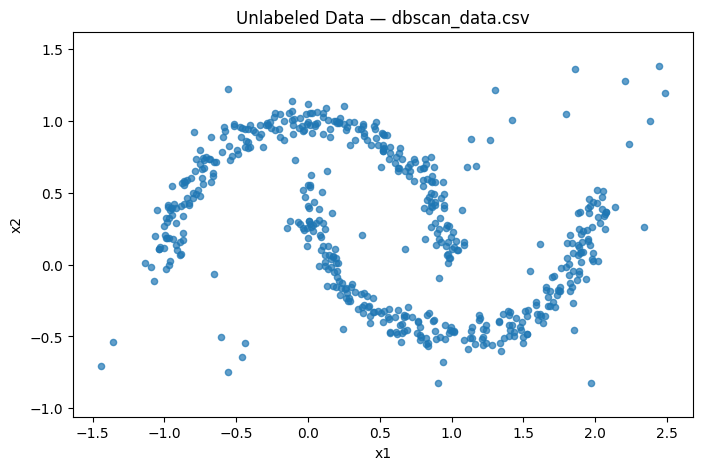

In [3]:
# 정답 Label이 없는 Data를 같은 색으로 나타낸다.
plt.figure(figsize=(8, 5))
plt.scatter(X['x1'], X['x2'], s=20, alpha=0.7)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Unlabeled Data — dbscan_data.csv')
plt.axis('equal')
plt.show()

## Neighborhood — What Does eps Mean?

DBSCAN은 Sample $X_i$를 중심으로 반경 `eps` 안에 있는 Samples를 찾는다.

$$
N_{\mathrm{eps}}(X_i)=\{X_j: \|X_j-X_i\|\leq \mathrm{eps}\}
$$

- `eps`: 같은 이웃으로 인정할 최대 Distance
- `min_samples`: 밀집된 영역으로 인정하기 위한 최소 Sample 수
- `min_samples`에는 기준 Sample 자기 자신도 포함한다.

2차원에서는 `eps`가 원의 반지름이다. 큰 `eps`를 사용하면 더 멀리 있는 Sample까지 이웃으로 인정한다.

## Core, Border, Noise

DBSCAN은 Sample을 세 종류로 구분한다.

- Core: 반경 `eps` 내에 자기 자신을 포함해 `min_samples`개 이상 존재한다.
- Border: Core는 아니지만 어떤 Core의 반경 `eps` 안에 있다.
- Noise: Core도 Border도 아니다. 결과 Label은 `-1`이다.

중요한 차이: Core는 이웃을 따라 Cluster를 확장할 수 있지만, Border는 이웃을 확장하는 출발점이 되지 않는다.

In [4]:
# 7개의 작은 Sample로 Core, Border, Noise를 직접 확인한다.
toy = pd.DataFrame({
    'x1': [0.00, 0.10, 0.00, 0.10, 0.27, 0.48, 0.95],
    'x2': [0.00, 0.00, 0.10, 0.10, 0.10, 0.10, 0.80]
}, index=list('ABCDEFG'))

example_eps = 0.20
example_min_samples = 4

neighbor_model = NearestNeighbors(radius=example_eps).fit(toy)
neighbor_indices = neighbor_model.radius_neighbors(
    toy, return_distance=False
)
neighbor_counts = np.array([len(indices) for indices in neighbor_indices])

toy_dbscan = DBSCAN(
    eps=example_eps, min_samples=example_min_samples
).fit(toy)

is_core = np.zeros(len(toy), dtype=bool)
is_core[toy_dbscan.core_sample_indices_] = True

sample_types = np.where(
    toy_dbscan.labels_ == -1, 'Noise',
    np.where(is_core, 'Core', 'Border')
)

toy_result = toy.copy()
toy_result['Neighbors (including self)'] = neighbor_counts
toy_result['Type'] = sample_types
toy_result['Cluster'] = toy_dbscan.labels_
print(toy_result)

     x1   x2  Neighbors (including self)    Type  Cluster
A  0.00  0.0                           4    Core        0
B  0.10  0.0                           5    Core        0
C  0.00  0.1                           4    Core        0
D  0.10  0.1                           5    Core        0
E  0.27  0.1                           3  Border        0
F  0.48  0.1                           1   Noise       -1
G  0.95  0.8                           1   Noise       -1


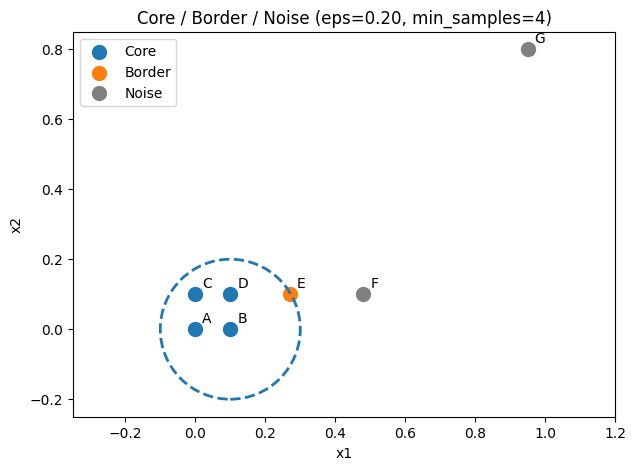

In [5]:
# Sample B를 중심으로 eps Neighborhood를 시각화한다.
fig, ax = plt.subplots(figsize=(7, 5))

type_colors = {'Core': 'tab:blue', 'Border': 'tab:orange', 'Noise': 'gray'}
for sample_type in ['Core', 'Border', 'Noise']:
    mask = toy_result['Type'] == sample_type
    ax.scatter(toy.loc[mask, 'x1'], toy.loc[mask, 'x2'],
               s=100, color=type_colors[sample_type], label=sample_type)

for name, row in toy.iterrows():
    ax.annotate(name, (row['x1'], row['x2']), xytext=(5, 5),
                textcoords='offset points')

center = toy.loc['B', ['x1', 'x2']].to_numpy(dtype=float)
ax.add_patch(Circle(center, example_eps, fill=False,
                    linewidth=2, linestyle='--', edgecolor='tab:blue'))

ax.set_title('Core / Border / Noise (eps=0.20, min_samples=4)')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.axis('equal')
ax.legend()
plt.show()

## How Does DBSCAN Form Clusters?

Clustering 과정은 다음과 같이 이해할 수 있다.

- 아직 방문하지 않은 Sample을 선택한다.
- `eps` Neighborhood에 `min_samples`개 이상 있으면 Core이다.
- Core의 이웃들을 같은 Cluster에 포함하고, 새 Core의 이웃도 계속 확장한다.
- 다른 밀집 영역에서 새로운 Cluster를 만든다.
- 어떤 Cluster에도 포함되지 않은 Sample은 Noise(`-1`)로 남는다.

K-Means의 `Assignment → Update`와 달리, DBSCAN에서는 Centroid를 반복 이동하지 않는다.

## DBSCAN with scikit-learn

본 강의용 Data에는 다음 설정을 먼저 적용한다.

- `eps=0.12`: 이웃의 반경
- `min_samples=6`: Core로 인정할 최소 Sample 수 (자기 자신 포함)

`fit_predict()`는 각 Sample에 대한 Cluster Label을 반환한다. Label `-1`은 Noise이다.

In [6]:
# 두 Feature만 사용해 DBSCAN을 실행한다.
dbscan = DBSCAN(eps=0.12, min_samples=6)
labels = dbscan.fit_predict(X)

# Noise(-1)는 Cluster 개수에서 제외한다.
n_clusters = len(set(labels) - {-1})
n_noise = int(np.sum(labels == -1))

print('Clusters:', n_clusters)
print('Noise Samples:', n_noise)
print('Cluster Counts (including Noise):')
print(pd.Series(labels).value_counts().sort_index())

Clusters: 2
Noise Samples: 38
Cluster Counts (including Noise):
-1     38
 0    260
 1    257
Name: count, dtype: int64


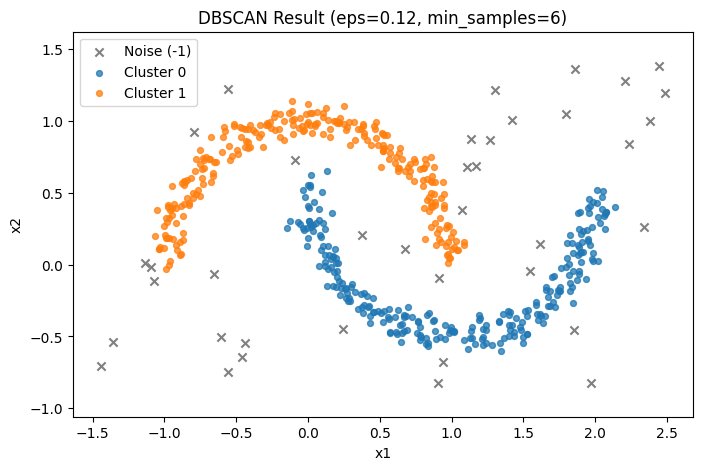

In [7]:
# Cluster 번호에 따라 색을 구별하고 Noise(-1)는 회색으로 표시한다.
plt.figure(figsize=(8, 5))

for label in sorted(set(labels)):
    mask = (labels == label)
    if label == -1:
        plt.scatter(X.loc[mask, 'x1'], X.loc[mask, 'x2'],
                    c='gray', marker='x', s=35, label='Noise (-1)')
    else:
        plt.scatter(X.loc[mask, 'x1'], X.loc[mask, 'x2'],
                    s=18, alpha=0.75, label=f'Cluster {label}')

plt.xlabel('x1')
plt.ylabel('x2')
plt.title('DBSCAN Result (eps=0.12, min_samples=6)')
plt.axis('equal')
plt.legend()
plt.show()

## Identifying Core and Border Samples

`dbscan.core_sample_indices_`에는 Core Samples의 위치가 저장되어 있다.

- Core: Cluster를 확장할 수 있는 Sample
- Border: Cluster에 포함되었지만 Core는 아닌 Sample
- Noise: Cluster가 없는 Sample (`-1`)

Cluster 번호는 발견된 Group의 식별자일 뿐이다. 예를 들어 `Cluster 0`이 특별한 의미를 가지지는 않는다.

Core Samples: 508
Border Samples: 9
Noise Samples: 38


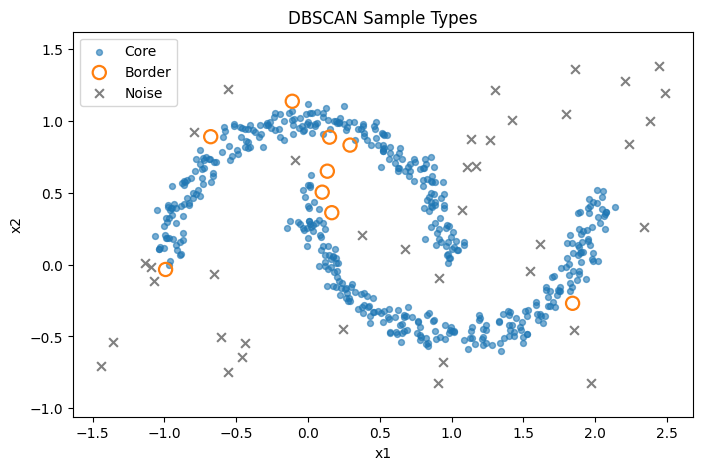

In [8]:
# 실제 Data에서 Core / Border / Noise 개수를 계산한다.
core_mask = np.zeros(len(X), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True

border_mask = (labels != -1) & (~core_mask)
noise_mask = (labels == -1)

print('Core Samples:', int(core_mask.sum()))
print('Border Samples:', int(border_mask.sum()))
print('Noise Samples:', int(noise_mask.sum()))

plt.figure(figsize=(8, 5))
plt.scatter(X.loc[core_mask, 'x1'], X.loc[core_mask, 'x2'],
            c='tab:blue', s=18, alpha=0.6, label='Core')
plt.scatter(X.loc[border_mask, 'x1'], X.loc[border_mask, 'x2'],
            facecolors='none', edgecolors='tab:orange', s=90,
            linewidths=1.6, label='Border')
plt.scatter(X.loc[noise_mask, 'x1'], X.loc[noise_mask, 'x2'],
            c='gray', marker='x', s=40, label='Noise')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('DBSCAN Sample Types')
plt.axis('equal')
plt.legend()
plt.show()

## Comparing K-Means and DBSCAN

같은 Data에 K-Means와 DBSCAN을 적용해 보자.

- K-Means는 모든 Sample을 두 Centroid 중 더 가까운 곳에 할당한다.
- DBSCAN은 밀집된 영역을 연결한다. Noise는 Cluster에 포함시키지 않을 수 있다.
- 아래 비교에서 K-Means에 `k=2`를 지정하는 것은 두 굽은 Group을 구별할 수 있는지 비교하기 위해서다.

비교의 목적은 모든 Data에서 DBSCAN이 더 좋다는 것을 증명하는 것이 아니라, Cluster의 형태에 따라 적절한 방법이 달라질 수 있다는 점을 확인하는 것이다.

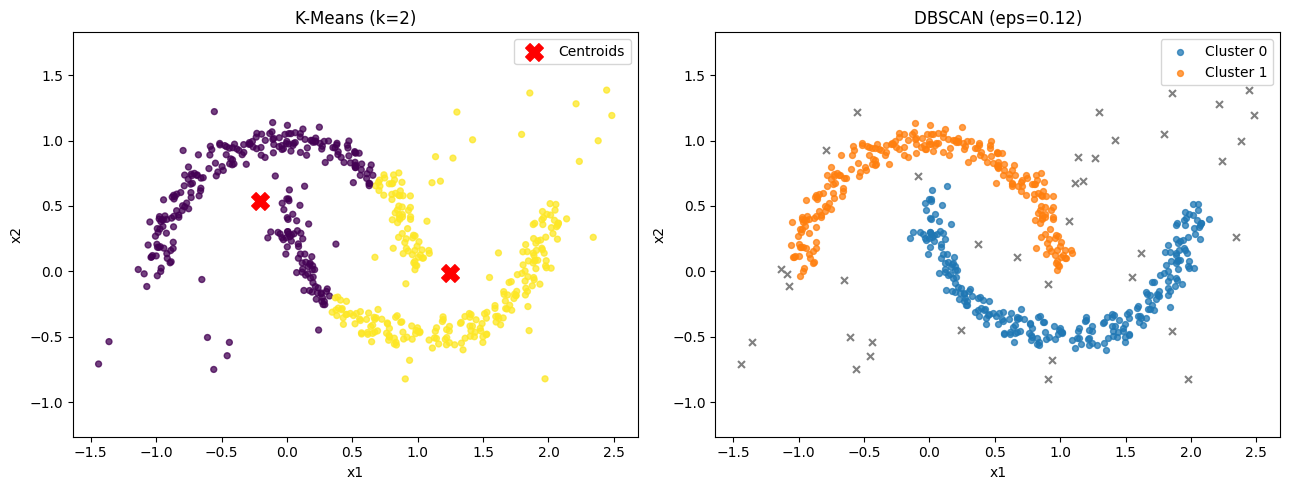

In [9]:
# 동일한 Data에서 Centroid 기반 방법과 Density 기반 방법을 비교한다.
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X['x1'], X['x2'], c=km_labels,
                cmap='viridis', s=18, alpha=0.75)
axes[0].scatter(kmeans.cluster_centers_[:, 0],
                kmeans.cluster_centers_[:, 1],
                c='red', marker='X', s=160, label='Centroids')
axes[0].set_title('K-Means (k=2)')
axes[0].legend()

for label in sorted(set(labels)):
    mask = labels == label
    if label == -1:
        axes[1].scatter(X.loc[mask, 'x1'], X.loc[mask, 'x2'],
                        c='gray', marker='x', s=25)
    else:
        axes[1].scatter(X.loc[mask, 'x1'], X.loc[mask, 'x2'],
                        s=18, alpha=0.75, label=f'Cluster {label}')
axes[1].set_title('DBSCAN (eps=0.12)')
axes[1].legend()

for ax in axes:
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.axis('equal')

plt.tight_layout()
plt.show()

## What Happens If We Change eps?

`min_samples=6`을 유지하고 `eps`만 변경해 본다.

- `eps`가 너무 작으면 이웃이 부족해 Group이 여러 조각으로 나뉘거나 Noise가 늘 수 있다.
- 적절한 `eps`에서는 각 밀집 Group이 하나의 Cluster가 된다.
- `eps`가 너무 크면 원래 다른 Group이 하나로 연결될 수 있다.

Cluster 수만으로 좋은 결과를 판단할 수는 없다. Data의 모양과 Noise도 함께 보아야 한다.

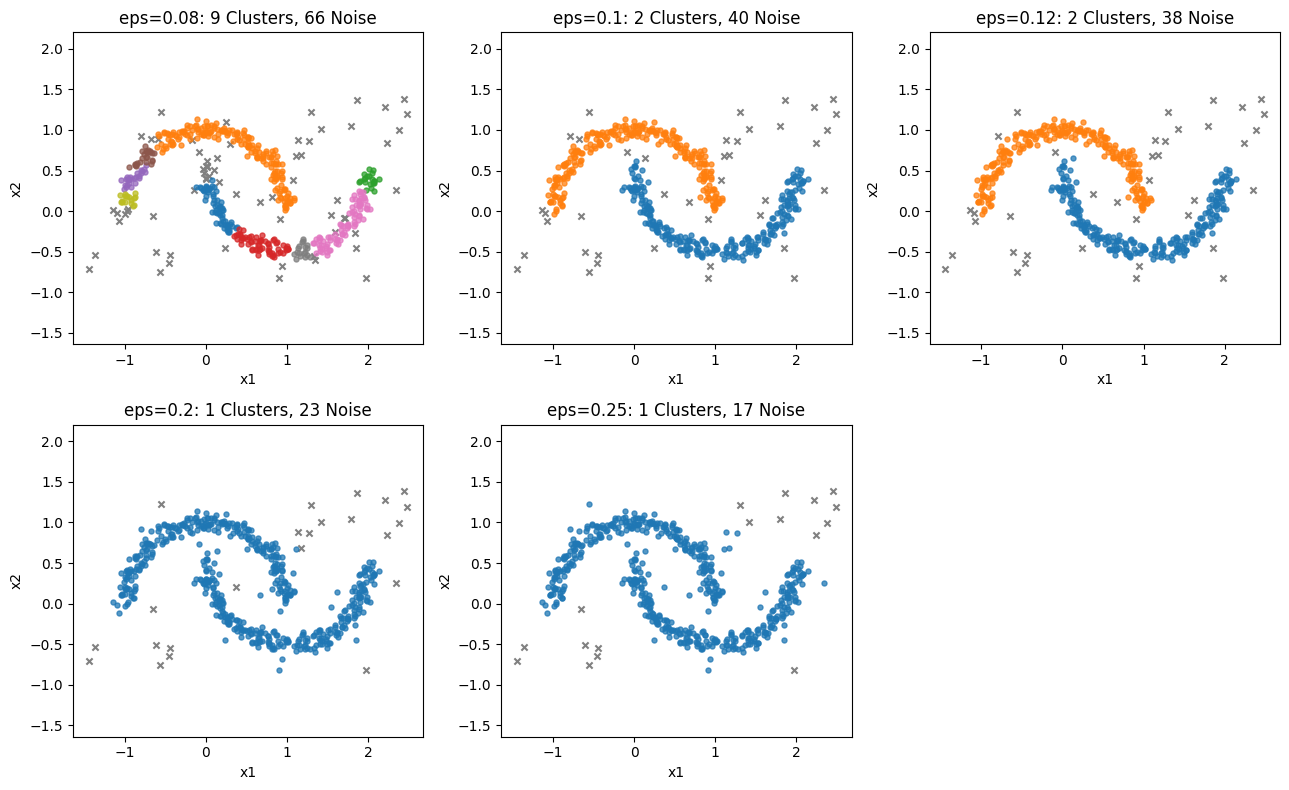

In [12]:
# eps를 변경하면서 실제 Cluster 모양을 비교한다.
eps_values = [0.08, 0.10, 0.12, 0.20, 0.25]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for ax, eps in zip(axes.ravel(), eps_values):
    result = DBSCAN(eps=eps, min_samples=6).fit_predict(X)
    cluster_count = len(set(result) - {-1})
    noise_count = int(np.sum(result == -1))

    for label in sorted(set(result)):
        mask = result == label
        if label == -1:
            ax.scatter(X.loc[mask, 'x1'], X.loc[mask, 'x2'],
                       c='gray', marker='x', s=20)
        else:
            ax.scatter(X.loc[mask, 'x1'], X.loc[mask, 'x2'],
                       s=13, alpha=0.75)

    ax.set_title(f'eps={eps}: {cluster_count} Clusters, {noise_count} Noise')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.axis('equal')

axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

In [13]:
# eps별 Cluster 수와 Noise 수를 표로 정리한다.
results = []

for eps in eps_values:
    result = DBSCAN(eps=eps, min_samples=6).fit_predict(X)
    n_clusters = len(set(result) - {-1})
    n_noise = int(np.sum(result == -1))

    results.append({
        'eps': eps,
        'Clusters': n_clusters,
        'Noise Samples': n_noise,
        'Noise Ratio (%)': round(n_noise / len(X) * 100, 1)
    })

result_table = pd.DataFrame(results)
print(result_table.to_string(index=False))

 eps  Clusters  Noise Samples  Noise Ratio (%)
0.08         9             66             11.9
0.10         2             40              7.2
0.12         2             38              6.8
0.20         1             23              4.1
0.25         1             17              3.1


## What Happens If We Change min_samples?

`min_samples`도 사용자가 지정하는 Hyperparameter이다.

- 같은 `eps`에서 `min_samples`를 크게 하면 Core의 조건이 더 엄격해진다.
- Core가 줄어들면서 Noise가 늘거나 Cluster가 분리될 수 있다.
- `min_samples`를 작게 하면 작은 밀집 영역도 Cluster로 인정될 수 있다.

`eps`와 `min_samples`는 서로 영향을 주므로 함께 고려해야 한다.

In [14]:
# eps는 고정하고 min_samples만 변경한다.
min_samples_values = [3, 6, 10, 18]

for n in min_samples_values:
    result = DBSCAN(eps=0.12, min_samples=n).fit_predict(X)
    n_clusters = len(set(result) - {-1})
    n_noise = int(np.sum(result == -1))
    print(f'min_samples={n:2d}: Clusters={n_clusters}, Noise={n_noise}')

min_samples= 3: Clusters=2, Noise=35
min_samples= 6: Clusters=2, Noise=38
min_samples=10: Clusters=2, Noise=45
min_samples=18: Clusters=12, Noise=165


## How Can We Choose eps? — Nearest Neighbor Distance

`eps`를 선택할 때 Neighbor Distance의 분포를 참고할 수 있다.

- `min_samples=6`이라면 각 Sample에서 자기 자신을 포함한 여섯 번째 가까운 Sample까지의 Distance를 계산한다.
- 각 Distance를 작은 값부터 정렬하여 그린다.
- 거리 값이 급격하게 증가하는 부분을 `eps`의 후보로 고려할 수 있다.

이 방법이 항상 명확한 최적값을 주는 것은 아니다. 최종적으로 Cluster 모양과 Noise 수를 함께 확인한다.

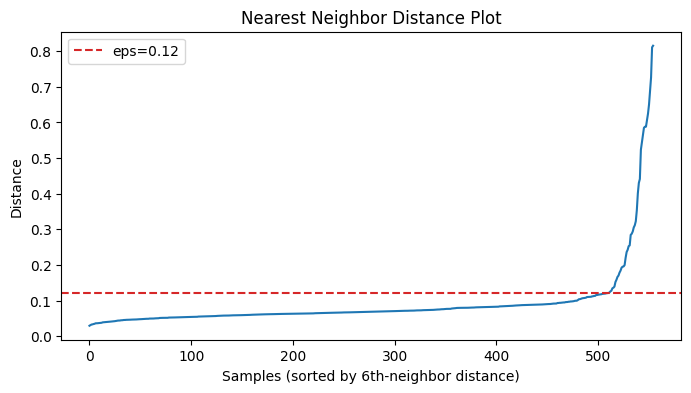

In [15]:
# 6번째 가까운 Neighbor의 Distance를 계산한다 (자기 자신 포함).
neighbor_model = NearestNeighbors(n_neighbors=6)
neighbor_model.fit(X)

distances, _ = neighbor_model.kneighbors(X)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.axhline(0.12, color='tab:red', linestyle='--', label='eps=0.12')
plt.xlabel('Samples (sorted by 6th-neighbor distance)')
plt.ylabel('Distance')
plt.title('Nearest Neighbor Distance Plot')
plt.legend()
plt.show()

## Feature Scale and DBSCAN

DBSCAN은 Distance로 이웃을 판단하므로 Feature의 단위가 중요하다.

- 예를 들어 `x2`에만 10을 곱하면 Data 사이의 Distance가 바뀐다.
- 이때 같은 `eps`를 그대로 사용하면 Clustering 결과가 크게 달라질 수 있다.
- 실제 Data의 Feature Scale이 다르면 `StandardScaler` 등을 고려하고, Scale을 바꾼 뒤에는 `eps`도 다시 선택해야 한다.

In [16]:
# x2의 Scale만 10배로 바꾸고 같은 eps를 적용해 본다.
X_changed = X.copy()
X_changed['x2'] = X_changed['x2'] * 10

changed_labels = DBSCAN(eps=0.12, min_samples=6).fit_predict(X_changed)
changed_clusters = len(set(changed_labels) - {-1})
changed_noise = int(np.sum(changed_labels == -1))

print('Original: Clusters =', len(set(labels) - {-1}),
      ', Noise =', np.sum(labels == -1))
print('Changed Scale: Clusters =', changed_clusters,
      ', Noise =', changed_noise)

Original: Clusters = 2 , Noise = 38
Changed Scale: Clusters = 7 , Noise = 511


## Summary — DBSCAN

- K-Means는 Centroid를 사용하지만 DBSCAN은 밀집된 Neighborhood로 Cluster를 찾는다.
- `eps`는 이웃으로 인정할 Distance이며, `min_samples`는 Core의 최소 이웃 수이다.
- Core는 Cluster 확장을 주도하고, Border는 Cluster에 포함되지만 확장하지 않는다.
- Noise는 Label `-1`로 구분한다.
- 굽은 Group을 찾을 수 있지만, 밀도가 크게 다른 Group을 한 번에 잘 구별하기는 어렵다.
- Feature Scale과 `eps` 선택에 따라 결과가 크게 달라진다.

다음 25강에서는 Hierarchical Clustering을 이용하여 Data의 계층적 Group 구조를 살펴본다.

## Homework - Problem 24

`dbscan_data2.csv`를 이용하여 DBSCAN Clustering을 수행하시오.

다음 조건을 사용한다.

- Feature: `x1`, `x2`
- `min_samples=6`
- `eps=0.08, 0.10, 0.12, 0.20`
- DBSCAN에서 Noise의 Label은 `-1`이다.

다음 질문에 답하시오.

- 각 `eps`에 대해 Noise를 제외한 Cluster 수를 적으시오.
- 각 `eps`에 대해 Noise Sample 수를 적으시오.
- 위 네 `eps` 중 Cluster가 정확히 2개인 값들을 모두 적으시오.

강의에서 사용한 Code의 Data File과 `eps` 값만 변경하여 실행할 수 있다.

답만 제출하시오.